In [1]:
import pandas as pd
df= pd.read_csv("../Datasets/titanic.csv")
df.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


In [2]:
print("columns, rows:", df.shape)

columns, rows: (891, 12)


#### Data Preparation (We don't want many columns so we are droping uncessary columns)

In [3]:
#droping columns
df= df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])
df.columns

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked'],
      dtype='object')

In [4]:
#filling nan values
df['Age']= df['Age'].fillna(df['Age'].median())

df['Embarked']= df['Embarked'].fillna(df['Embarked'].mode()[0]) #select the first returned mode

In [5]:
#turning text columns into numeric 0/1 columns by One-Hot Encoding
df= pd.get_dummies(df, columns= ["Sex", "Embarked"], drop_first=True)

In [6]:
print('missing values left:', df.isnull().sum().sum())
df.head()

missing values left: 0


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,True,False,True
1,1,1,38.0,1,0,71.2833,False,False,False
2,1,3,26.0,0,0,7.9250,False,False,True
3,1,1,35.0,1,0,53.1000,False,False,True
4,0,3,35.0,0,0,8.0500,True,False,True


#### Features, target and train_test_split

In [7]:
from sklearn.model_selection import train_test_split

X= df.drop(columns= "Survived")
y= df["Survived"]

X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.2, stratify=y, random_state=2)

print("train:", X_train.shape[0], "test:", X_test.shape[0])

train: 712 test: 179


### Step: 1 --> A single decision tree
lets start with one fully-grown decision tree as our base line, we'll print its train and test accuracy (to stop overfitting) and the classification report

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

tree= DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

#Accuracy
print("Decision Tree - train_accuracy:", round(tree.score(X_train, y_train), 3))
print("Decision Tree - test_accuracy:", round(tree.score(X_test, y_test), 3))

#classification_report
print(classification_report(y_test, tree.predict(X_test), target_names=["died", "survived"]))

Decision Tree - train_accuracy: 0.985
Decision Tree - test_accuracy: 0.76
              precision    recall  f1-score   support

        died       0.80      0.82      0.81       110
    survived       0.70      0.67      0.68        69

    accuracy                           0.76       179
   macro avg       0.75      0.74      0.74       179
weighted avg       0.76      0.76      0.76       179



In [ ]:
# tree.fit(X_train, y_train)       # Learn from training data

# y_pred = tree.predict(X_test)    # Predict using unseen features

# classification_report(
#     y_test,                      # Compare with actual answers
#     y_pred                       # Compare against predictions
# )

### 2. Random Forest

RandomForestClassifier trains a whole ensemble of trees (default 100) and has them vote. same fit/predict interface before

In [11]:
from sklearn.ensemble import RandomForestClassifier

forest= RandomForestClassifier(n_estimators=100, random_state=42)
forest.fit(X_train, y_train)

print("Random Forest - train_accuracy:", round(forest.score(X_train, y_train), 3))
print("Random Forest - test_accuracy:", round(forest.score(X_test, y_test), 3))

#classification_report
print(classification_report(y_test, tree.predict(X_test), target_names=["died", "survived"]))

Random Forest - train_accuracy: 0.985
Random Forest - test_accuracy: 0.816
              precision    recall  f1-score   support

        died       0.80      0.82      0.81       110
    survived       0.70      0.67      0.68        69

    accuracy                           0.76       179
   macro avg       0.75      0.74      0.74       179
weighted avg       0.76      0.76      0.76       179



#### Now see our model learned from the train data and improved its accuracy

In [12]:
#testing whether using more Decision Trees improves Random Forest's test accuracy. 

for n in [10, 100]:
    rf= RandomForestClassifier(n, random_state=42)
    rf.fit(X_train, y_train)
    print(f'{n:>3} trees --> test accuracy= {rf.score(X_test, y_test):.3f}')


 10 trees --> test accuracy= 0.821
100 trees --> test accuracy= 0.816


#### Ploting feature_importances_

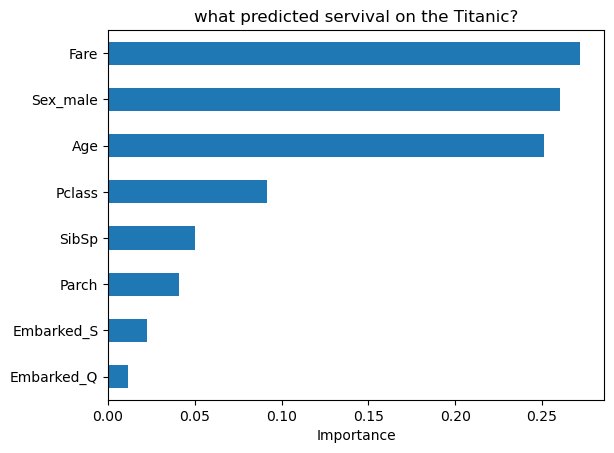

In [14]:
import matplotlib.pyplot as plt

importance= pd.Series(forest.feature_importances_, index= X.columns).sort_values()

importance.plot(kind= "barh")

plt.xlabel("Importance")
plt.title("what predicted servival on the Titanic?")
plt.show()